### Imports

In [1]:
import sys

sys.path.append("..")
import importlib
import os
import random
from pathlib import Path

import numpy as np
from PIL import Image

import src.data.transforms

importlib.reload(src.data.transforms)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, models, transforms

import src.data.transforms as t

%matplotlib inline

### Hyperparameters & Configurations

In [2]:
MODEL_TYPE = "resnet"

IMG_SIZE = 224
BATCH_SIZE = 256
EPOCHS = 5
LR = 0.001

ASL_MEAN = 0.5068
ASL_STD = 0.2424

# data split ratios
TRAIN_SPLIT = 0.70
VAL_SPLIT = 0.15
TEST_SPLIT = 0.15

# data path
DATA_DIR = "../data/asl_alphabet_train"
CROP_PADDING = 20

### Reproducibility & Device setup

In [3]:
# set random seeds
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print(f"All random seeds are set to {seed}")

All random seeds are set to 42


In [4]:
# device setup
device = (
    torch.accelerator.current_accelerator().type
    if torch.accelerator.is_available()
    else "cpu"
)
print(f"Using {device} device")

Using cuda device


### Data Transforms

In [5]:
train_transforms, val_transforms = t.get_transforms(
    model_type=MODEL_TYPE,
    img_size=IMG_SIZE,
    crop_padding=CROP_PADDING,
)

#### Visualize transfoms work

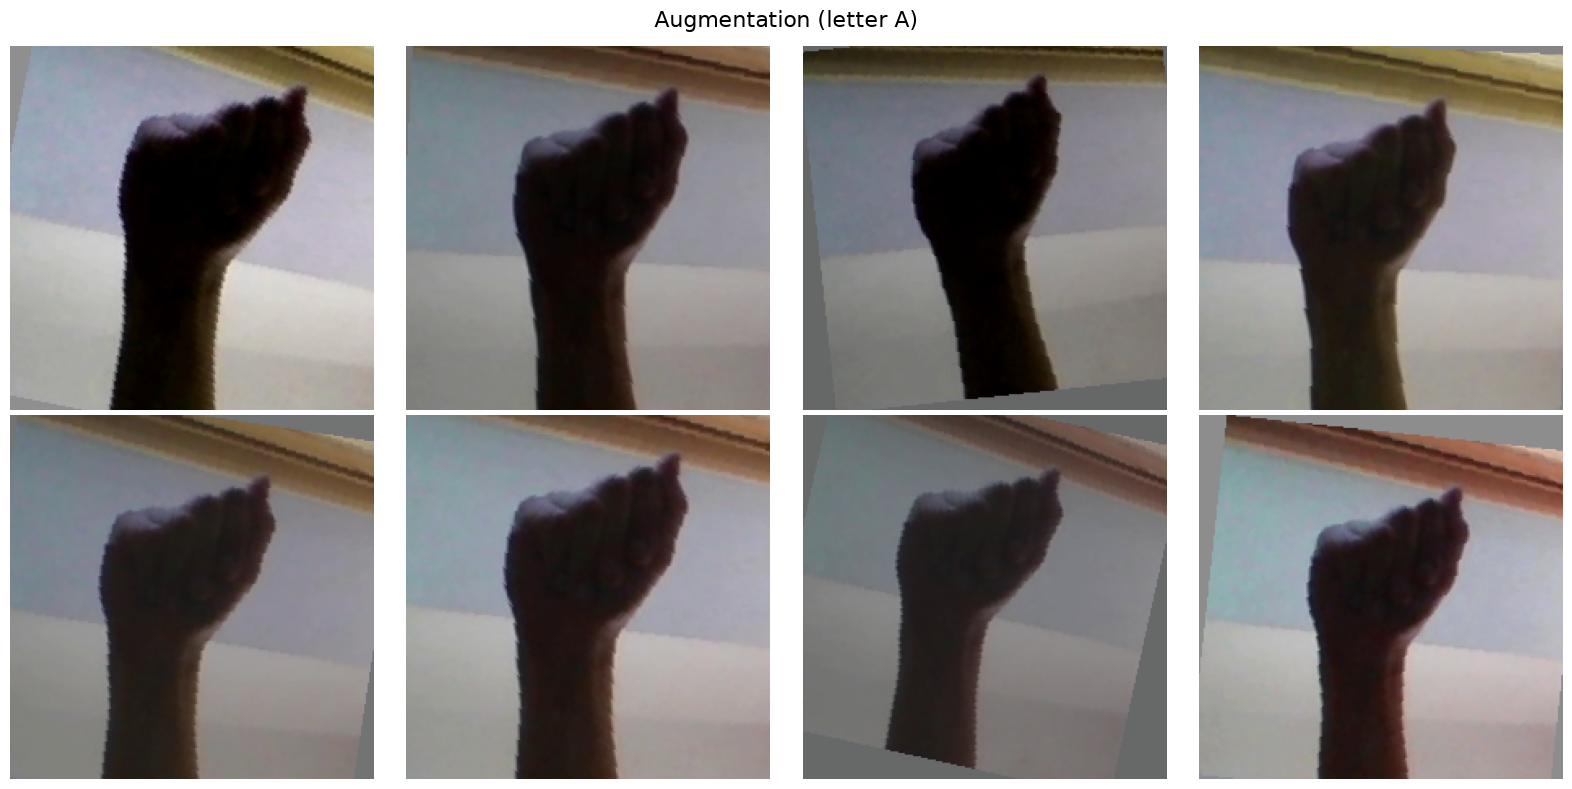

In [6]:
img = Image.open("../data/asl_alphabet_train/A/A1.jpg").convert("RGB")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax in axes.flat:
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    aug_img = train_transforms(img)  # [3, H, W]
    aug_np = aug_img.permute(1, 2, 0).numpy()  # [H, W, 3]
    aug_np = aug_np * std + mean  # денормализация
    aug_np = np.clip(aug_np, 0, 1)
    ax.imshow(aug_np)
    ax.axis("off")
plt.suptitle("Augmentation (letter A)", fontsize=16)
plt.tight_layout()
plt.savefig("../reports/figures/augmentation.png", dpi=150)
plt.show()

### Splitting Dataset

In [6]:
# load dataset
full_dataset = datasets.ImageFolder(root=DATA_DIR, transform=None)

In [7]:
# split the data
dataset_size = len(full_dataset)
train_size = int(TRAIN_SPLIT * dataset_size)  # 0.7
val_size = int(VAL_SPLIT * dataset_size)  # 0.15
test_size = dataset_size - train_size - val_size  # 0.15

generator = torch.Generator().manual_seed(seed)
train_indices, val_indices, test_indices = random_split(
    range(dataset_size), [train_size, val_size, test_size], generator=generator
)

# Create subset of datasets
train_ds = t.TransformSubset(full_dataset, train_indices, transform=train_transforms)
val_ds = t.TransformSubset(full_dataset, val_indices, transform=val_transforms)
test_ds = t.TransformSubset(full_dataset, test_indices, transform=val_transforms)

In [8]:
# Dataloaders
train_dataloader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=8,
    pin_memory=True,
    persistent_workers=True,
)
val_dataloader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    persistent_workers=True,
)
test_dataloader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    persistent_workers=True,
)

print(f"Total images: {dataset_size}")
print(f"Train: {len(train_ds)} ({len(train_ds) / dataset_size:.1%})")
print(f"Val:   {len(val_ds)} ({len(val_ds) / dataset_size:.1%})")
print(f"Test:  {len(test_ds)} ({len(test_ds) / dataset_size:.1%})")

Total images: 87000
Train: 60899 (70.0%)
Val:   13050 (15.0%)
Test:  13051 (15.0%)


### Model Definition

In [10]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

print(f"\nПараметров: {sum(p.numel() for p in model.parameters()):,}")

# Замена головы
model.fc = torch.nn.Linear(model.fc.in_features, 29)

# Сначала замораживаем ВСЁ
for param in model.parameters():
    param.requires_grad = False

# Размораживаем ТОЛЬКО голову
for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_params = total_params - trainable_params

print(f"Всего параметров:     {total_params:,}")
print(f"Обучаемых (голова):   {trainable_params:,}")
print(f"Замороженных:         {frozen_params:,}")
print(f"Доля обучаемых:       {trainable_params / total_params:.2%}")

# Проверка по слоям
print("\nТребуют градиента:")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(f"  {name}: {param.shape}")


Параметров: 11,689,512
Всего параметров:     11,191,389
Обучаемых (голова):   14,877
Замороженных:         11,176,512
Доля обучаемых:       0.13%

Требуют градиента:
  fc.weight: torch.Size([29, 512])
  fc.bias: torch.Size([29])


In [14]:
# Optimize the model
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=LR, weight_decay=1e-4)

# LR Scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, factor=0.5, patience=2, mode="min", min_lr=1e-6
)

### Model Training

In [15]:
from src.train.trainer import train_epoch, validate

In [16]:
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "lr": [],
}

best_val_acc = 0.0
best_epoch = 0
patience_counter = 0
EARLY_STOPPING_PATIENCE = 5

In [17]:
for epoch in range(EPOCHS):
    print(f"\n{'=' * 60}")
    print(f"Epoch {epoch}/{EPOCHS}")
    print(f"{'=' * 60}")

    # Train
    train_loss, train_acc = train_epoch(
        model, train_dataloader, optimizer, criterion, device
    )

    # Validate
    val_loss, val_acc = validate(model, val_dataloader, criterion, device)

    # Scheduler step (по val_loss)
    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    # История
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["lr"].append(current_lr)

    print(f"Train: loss={train_loss:.4f}, acc={train_acc:.4f}")
    print(f"Val:   loss={val_loss:.4f}, acc={val_acc:.4f}")
    print(f"LR:    {current_lr:.2e}")

    # Сохранение лучшей модели
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        patience_counter = 0
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_acc": val_acc,
                "val_loss": val_loss,
            },
            "../models/resnet_cnn_best.pth",
        )
        print(f"Новая лучшая модель! val_acc={val_acc:.4f}")
    else:
        patience_counter += 1

    # Early stopping
    if patience_counter >= EARLY_STOPPING_PATIENCE:
        print(f"\nEarly stopping на эпохе {epoch}")
        break

print(f"\n{'=' * 60}")
print("Обучение завершено!")
print(f"Лучшая эпоха: {best_epoch}")
print(f"Лучшая val_acc: {best_val_acc:.4f}")
print(f"{'=' * 60}")


Epoch 0/5


Train: loss=1.8014, acc=0.5929
Val:   loss=1.0864, acc=0.7900
LR:    1.00e-03
Новая лучшая модель! val_acc=0.7900

Epoch 1/5


Train: loss=0.9338, acc=0.7814
Val:   loss=0.7529, acc=0.8368
LR:    1.00e-03
Новая лучшая модель! val_acc=0.8368

Epoch 2/5


Train: loss=0.7313, acc=0.8174
Val:   loss=0.6328, acc=0.8497
LR:    1.00e-03
Новая лучшая модель! val_acc=0.8497

Epoch 3/5


Train: loss=0.6363, acc=0.8319
Val:   loss=0.5476, acc=0.8676
LR:    1.00e-03
Новая лучшая модель! val_acc=0.8676

Epoch 4/5


Train: loss=0.5780, acc=0.8422
Val:   loss=0.4875, acc=0.8792
LR:    1.00e-03
Новая лучшая модель! val_acc=0.8792

Обучение завершено!
Лучшая эпоха: 4
Лучшая val_acc: 0.8792


In [18]:
model.eval()

correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_dataloader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

print(f"Test Acc: {100 * correct / total:.2f}%")

Test Acc: 87.19%


### Fine tuning

In [23]:
checkpoint = torch.load("../models/resnet_cnn_best.pth", weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
print(f"Загружена модель с val_acc={checkpoint['val_acc']:.4f}")

for param in model.parameters():
    param.requires_grad = True

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Обучаемых: {trainable:,} / {total:,} ({trainable / total:.1%})")

Загружена модель с val_acc=0.8792
Обучаемых: 11,191,389 / 11,191,389 (100.0%)


In [24]:
optimizer_ft = optim.Adam(
    [
        # Ранние слои — маленький LR (не ломать края/текстуры)
        {"params": model.conv1.parameters(), "lr": 1e-5},
        {"params": model.bn1.parameters(), "lr": 1e-5},
        {"params": model.layer1.parameters(), "lr": 1e-5},
        # Средние слои — чуть больше
        {"params": model.layer2.parameters(), "lr": 5e-5},
        {"params": model.layer3.parameters(), "lr": 1e-4},
        # Поздние слои — больше (специфичны для ASL)
        {"params": model.layer4.parameters(), "lr": 5e-4},
        # Голова — самый большой LR
        {"params": model.fc.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-4,
)

scheduler_ft = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_ft, mode="min", factor=0.5, patience=2, min_lr=1e-7
)

criterion = nn.CrossEntropyLoss()
total_in_opt = sum(p.numel() for g in optimizer_ft.param_groups for p in g["params"])
print(f"В optimizer: {total_in_opt:,} / {total:,}")

for i, group in enumerate(optimizer_ft.param_groups):
    n = sum(p.numel() for p in group["params"])
    print(f"Group {i}: lr={group['lr']:.2e}, params={n:,}")

В optimizer: 11,191,389 / 11,191,389
Group 0: lr=1.00e-05, params=9,408
Group 1: lr=1.00e-05, params=128
Group 2: lr=1.00e-05, params=147,968
Group 3: lr=5.00e-05, params=525,568
Group 4: lr=1.00e-04, params=2,099,712
Group 5: lr=5.00e-04, params=8,393,728
Group 6: lr=1.00e-03, params=14,877


In [ ]:
history_ft = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "lr": [],
}

best_val_acc_ft = checkpoint["val_acc"]  # старт с FE (87.92%)
best_epoch_ft = 0
patience_counter_ft = 0

In [26]:
for epoch in range(EPOCHS):
    print(f"\n{'=' * 60}")
    print(f"Epoch {epoch}/{EPOCHS}")
    print(f"{'=' * 60}")

    # Train
    train_loss, train_acc = train_epoch(
        model, train_dataloader, optimizer_ft, criterion, device
    )

    # Validate
    val_loss, val_acc = validate(model, val_dataloader, criterion, device)

    # Scheduler step (по val_loss)
    scheduler_ft.step(val_loss)
    current_lr = optimizer_ft.param_groups[0]["lr"]

    # История
    history_ft["train_loss"].append(train_loss)
    history_ft["train_acc"].append(train_acc)
    history_ft["val_loss"].append(val_loss)
    history_ft["val_acc"].append(val_acc)
    history_ft["lr"].append(current_lr)

    print(f"Train: loss={train_loss:.4f}, acc={train_acc:.4f}")
    print(f"Val:   loss={val_loss:.4f}, acc={val_acc:.4f}")
    print(f"LR:    {current_lr:.2e}")

    # Сохранение лучшей модели
    if val_acc > best_val_acc_ft:
        best_val_acc_ft = val_acc
        best_epoch_ft = epoch
        patience_counter_ft = 0
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer_ft.state_dict(),
                "val_acc": val_acc,
                "val_loss": val_loss,
            },
            "../models/resnet18_finetuned.pth",
        )
        print(f"Новая лучшая модель! val_acc={val_acc:.4f}")
    else:
        patience_counter_ft += 1

    # Early stopping
    if patience_counter_ft >= EARLY_STOPPING_PATIENCE:
        print(f"\nEarly stopping на эпохе {epoch}")
        break

print(f"\n{'=' * 60}")
print("Обучение завершено!")
print(f"Лучшая эпоха: {best_epoch_ft}")
print(f"Лучшая val_acc: {best_val_acc_ft:.4f}")
print(f"{'=' * 60}")


Epoch 0/5


Train: loss=0.0430, acc=0.9865
Val:   loss=0.0059, acc=0.9978
LR:    1.00e-05
Новая лучшая модель! val_acc=0.9978

Epoch 1/5


Train: loss=0.0112, acc=0.9964
Val:   loss=0.0123, acc=0.9961
LR:    1.00e-05

Epoch 2/5


Train: loss=0.0065, acc=0.9981
Val:   loss=0.0006, acc=0.9999
LR:    1.00e-05
Новая лучшая модель! val_acc=0.9999

Epoch 3/5


Train: loss=0.0042, acc=0.9989
Val:   loss=0.0008, acc=0.9998
LR:    1.00e-05

Epoch 4/5


Train: loss=0.0068, acc=0.9979
Val:   loss=0.0039, acc=0.9988
LR:    1.00e-05

Обучение завершено!
Лучшая эпоха: 2
Лучшая val_acc: 0.9999


In [28]:
model.eval()

correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_dataloader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

print(f"Test Acc: {100 * correct / total:.2f}%")

Test Acc: 99.91%


### Test Evaluation

In [14]:
# Загружаем лучшую модель
checkpoint = torch.load("../models/resnet18_finetuned.pth", weights_only=False)

model = models.resnet18()

# Замена головы
model.fc = torch.nn.Linear(model.fc.in_features, 29)

model = model.to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"Загружена модель с эпохи {checkpoint['epoch']}")
print(f"Val accuracy: {checkpoint['val_acc']:.4f}")

Загружена модель с эпохи 2
Val accuracy: 0.9999


#### Сбор предсказаний на тесте

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# import numpy as np


@torch.no_grad()
def get_predictions(model, loader, device):
    model.eval()
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    return np.array(all_preds), np.array(all_labels)


# Собираем предсказания
y_pred, y_true = get_predictions(model, test_dataloader, device)

print(f"Всего примеров: {len(y_true)}")
print(f"Уникальных классов: {len(np.unique(y_true))}")

Всего примеров: 13051
Уникальных классов: 29


#### Расчёт метрик

In [16]:
# Accuracy
acc = accuracy_score(y_true, y_pred)

# Macro-усреднение (учитывает все классы одинаково)
precision_macro = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)

# Weighted-усреднение (учитывает размер классов)
f1_weighted = f1_score(y_true, y_pred, average="weighted", zero_division=0)

print("=" * 60)
print("Метрики на тесте")
print("=" * 60)
print(f"Accuracy:          {acc:.4f} ({acc * 100:.2f}%)")
print(f"Precision (macro): {precision_macro:.4f}")
print(f"Recall (macro):    {recall_macro:.4f}")
print(f"F1-score (macro):  {f1_macro:.4f}")
print(f"F1-score (weighted): {f1_weighted:.4f}")

Метрики на тесте
Accuracy:          0.9998 (99.98%)
Precision (macro): 0.9998
Recall (macro):    0.9998
F1-score (macro):  0.9998
F1-score (weighted): 0.9998


#### Classification Report

In [17]:
# Имена классов
class_names = test_dataloader.dataset.dataset.classes

# Отчёт по классам
print("\n" + "=" * 60)
print("Classification Report")
print("=" * 60)
print(
    classification_report(
        y_true, y_pred, target_names=class_names, digits=4, zero_division=0
    )
)


Classification Report
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       459
           B     1.0000    1.0000    1.0000       434
           C     1.0000    1.0000    1.0000       449
           D     1.0000    1.0000    1.0000       439
           E     1.0000    1.0000    1.0000       492
           F     1.0000    1.0000    1.0000       475
           G     1.0000    1.0000    1.0000       470
           H     1.0000    1.0000    1.0000       442
           I     1.0000    0.9977    0.9989       439
           J     1.0000    1.0000    1.0000       469
           K     0.9976    1.0000    0.9988       411
           L     1.0000    1.0000    1.0000       446
           M     1.0000    1.0000    1.0000       448
           N     1.0000    1.0000    1.0000       429
           O     1.0000    1.0000    1.0000       452
           P     1.0000    1.0000    1.0000       457
           Q     1.0000    1.0000    1.0000       450
    

#### Confusion Matrix

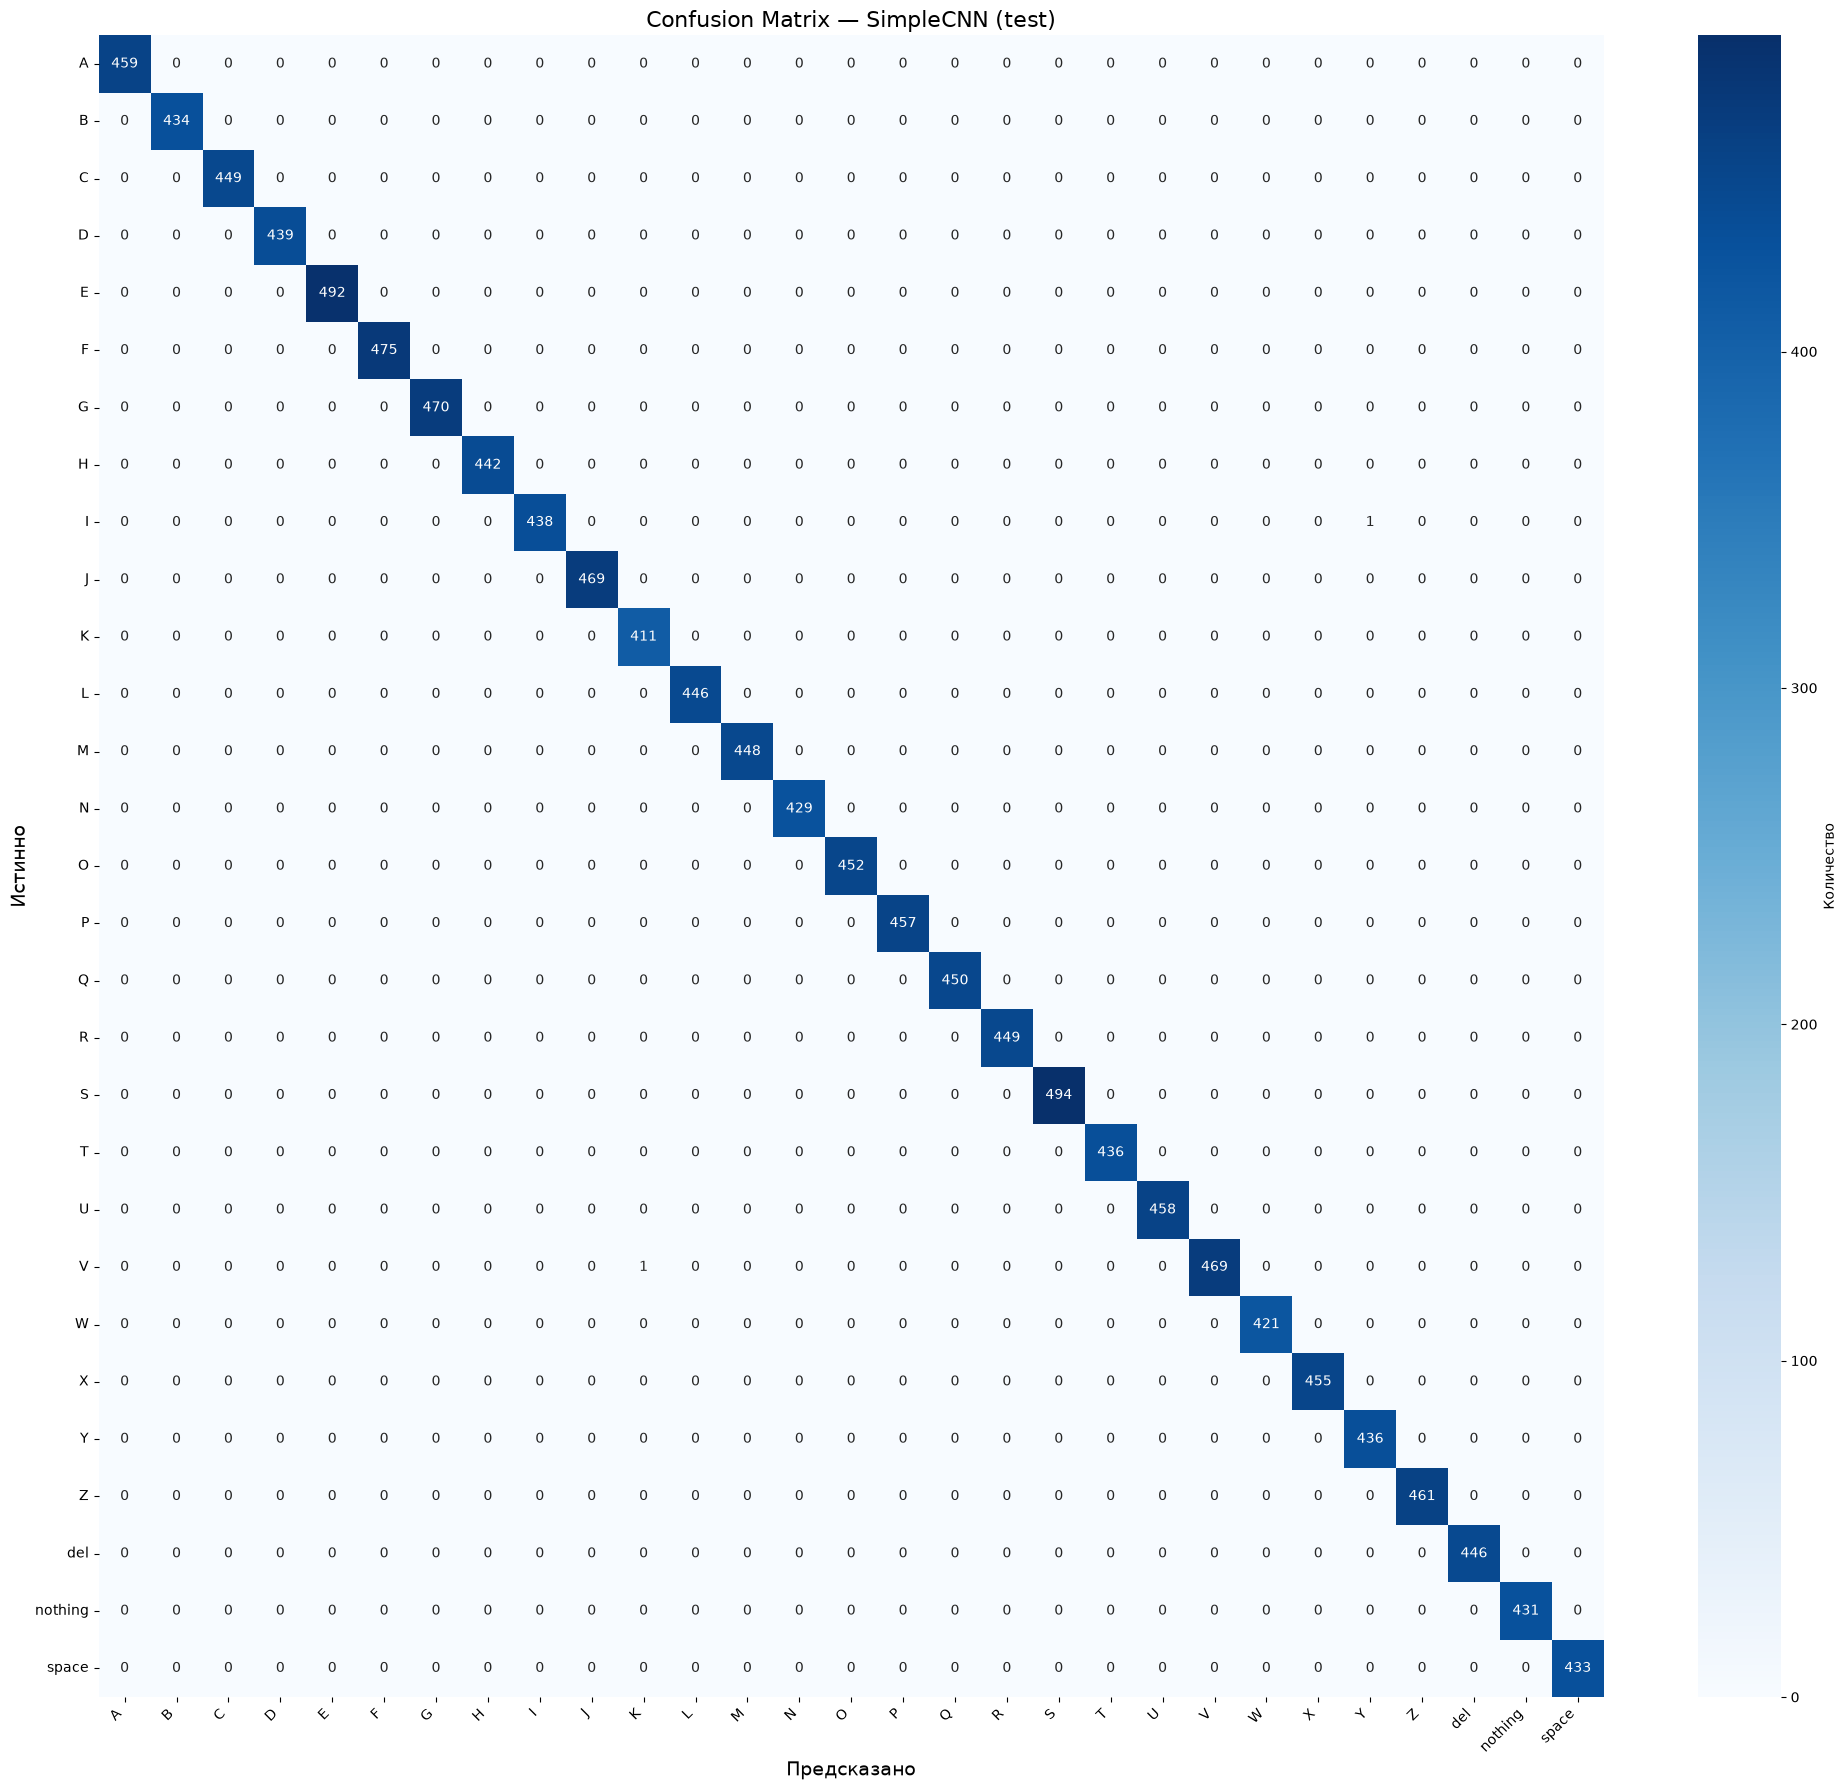

In [18]:
import matplotlib.pyplot as plt

# Матрица ошибок
cm = confusion_matrix(y_true, y_pred)

# Визуализация
plt.figure(figsize=(20, 18))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "Количество"},
)
plt.xlabel("Предсказано", fontsize=14)
plt.ylabel("Истинно", fontsize=14)
plt.title("Confusion Matrix — SimpleCNN (test)", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("../reports/figures/resnet18_confusion_matrix.png", dpi=150)
plt.show()